# Кейс 2. Прогнозирование оттока клиентов

Суть задачи простая: по данным о клиентах telecom-компании предсказать, кто из них
уйдёт в ближайшее время, и объяснить, почему. Одна строка — один клиент.

Смотрели на две метрики. ROC-AUC — потому что классы несбалансированы (73% против
27%) и нам важен порядок предсказаний, а не доля угаданных. Recall по классу
«ушёл» — потому что пропуск уходящего клиента стоит дороже, чем лишний звонок
тому, кто не собирался уходить. Accuracy тут вообще не показатель: просто
предсказав всем «остался», получишь те самые 73%.

Валидация — StratifiedKFold на 5 фолдов, вся предобработка живёт внутри Pipeline
и обучается только на train-части фолда, так что утечки исключены.

**Вклад участников**

| Участник | Вклад |
|---|---|
| Фамилия 1 | Загрузка данных, первичный осмотр, дубликаты |
| Фамилия 2 | EDA: распределения, корреляции, сегментный анализ, визуализация |
| Фамилия 3 | Формулировка гипотез, feature engineering (AvgCharges, N_Services, No_TechSupport) |
| Фамилия 4 | Предобработка, Pipeline, сравнение масштабирования, baseline |
| Фамилия 5 | Модели, GridSearch, RandomizedSearch, Optuna, эксперимент с SMOTE |
| Фамилия 6 | Подбор порога, финальная оценка, интерпретация (permutation importance, SHAP), список риска, выводы |

**Структура:** загрузка → EDA → гипотезы и новые признаки → предобработка →
масштабирование → baseline → сравнение моделей → тюнинг → Optuna → сэмплирование →
порог → интерпретация → список риска → выводы.

In [1]:
import sys

print("Python:", sys.version)
print("Путь:", sys.executable)

Python: 3.12.16 (main, Oct 26 2026, 14:10:56) [MSC v.1944 64 bit (AMD64)]
Путь: d:\01_Study\Case_02_Telco_Churn\.venv312\Scripts\python.exe


In [2]:
from pathlib import Path

print("Текущая папка:", Path.cwd())

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

print("Корень проекта:", project_root)

for folder in ["data", "src", "models", "notebooks"]:
    path = project_root / folder
    print(f"{folder}: {'OK' if path.is_dir() else 'НЕ НАЙДЕНА'}")

print("\nФайлы в data:")
data_dir = project_root / "data"

if data_dir.is_dir():
    for file in data_dir.rglob("*"):
        if file.is_file():
            print(file.relative_to(project_root))

Текущая папка: d:\01_Study\Case_02_Telco_Churn\notebooks
Корень проекта: d:\01_Study\Case_02_Telco_Churn
data: OK
src: OK
models: OK
notebooks: OK

Файлы в data:
data\processed\cleaned_data.csv
data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv


In [3]:
import sys
from pathlib import Path

project_root = Path.cwd().parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_utils import load_and_clean

df_test = load_and_clean()

print("Загрузка данных: OK")
print("Размер датасета:", df_test.shape)
print("Количество пропусков:", df_test.isna().sum().sum())
print("\nПервые 5 строк:")
display(df_test.head())

Загрузка данных: OK
Размер датасета: (7043, 20)
Количество пропусков: 0

Первые 5 строк:


,Пол,Пенсионер,Есть партнёр,Есть иждивенцы,Стаж,Телефония,Несколько линий,Интернет,Онлайн-защита,Облачный бэкап,Защита устройства,Техподдержка,Стриминг ТВ,Стриминг кино,Контракт,Электронный счёт,Способ оплаты,Платёж в месяц,Всего оплачено,Отток
customerID,,,,,,,,,,,,,,,,,,,,
7590-VHVEG,Женский,0,Да,Нет,1,Нет,Нет телефонии,DSL,Нет,Да,Нет,Нет,Нет,Нет,Помесячный,Да,Электронный чек,29.850000,29.850000,0
5575-GNVDE,Мужской,0,Нет,Нет,34,Да,Нет,DSL,Да,Нет,Да,Нет,Нет,Нет,Годовой,Нет,Чек по почте,56.950001,1889.500000,0
3668-QPYBK,Мужской,0,Нет,Нет,2,Да,Нет,DSL,Да,Да,Нет,Нет,Нет,Нет,Помесячный,Да,Чек по почте,53.849998,108.150002,1
7795-CFOCW,Мужской,0,Нет,Нет,45,Нет,Нет телефонии,DSL,Да,Нет,Да,Да,Нет,Нет,Годовой,Нет,Банковский перевод (авто),42.299999,1840.750000,0
9237-HQITU,Женский,0,Нет,Нет,2,Да,Нет,Оптоволокно,Нет,Нет,Нет,Нет,Нет,Нет,Помесячный,Да,Электронный чек,70.699997,151.649994,1


In [4]:
import os
from pathlib import Path
from threadpoolctl import threadpool_limits
import sys
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import shap
from scipy.stats import loguniform, randint
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, RobustScaler, StandardScaler

# Ищем корень проекта независимо от текущей рабочей папки.
PROJECT_ROOT = next((q for base in [Path.cwd(), *Path.cwd().parents]
                     for q in [base, base.parent]
                     if (q / "src" / "data_utils.py").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Не найден src/data_utils.py. Запускайте ноутбук из папки проекта или notebooks/.")
sys.path.insert(0, str(PROJECT_ROOT))
from src.data_utils import load_and_clean

warnings.filterwarnings("ignore", category=FutureWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
# Для первого запуска True: быстрый тест; для итоговых результатов False.
FAST_MODE = False
CV_FOLDS = 3 if FAST_MODE else 5
SEARCH_ITER = 8 if FAST_MODE else 40
OPTUNA_TRIALS = 8 if FAST_MODE else 50
N_JOBS = 2  # избегаем перегрузки памяти при вложенной параллелизации
MIN_RECALL = 0.75
CV = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
sns.set_theme(style="whitegrid")
PALETTE = {"Остался": "#4c9f70", "Ушёл": "#e4572e"}
CLASS_LABELS = {0: "Остался", 1: "Ушёл"}


### Режимы запуска и требования

- `FAST_MODE=True` — быстрый проверочный запуск (3 фолда, 8 случайных конфигураций, 8 испытаний Optuna).
- `FAST_MODE=False` — полный расчёт (5 фолдов, 40 конфигураций, 50 испытаний Optuna).
- Не запускайте отдельные ячейки в случайном порядке: **Kernel → Restart & Run All**.
- Нужны исходные данные и `src/data_utils.py` из вашего проекта. Ноутбук не включает эти файлы.
- Метрики старого запуска в текстовых выводах — исторические, не обещание идентичных результатов.
- Тестовая выборка используется для окончательной оценки; повторный подбор модели по её результатам недопустим.

## 1. Загрузка данных
Проверяем размер, долю целевого класса, пропуски и дубликаты.

In [5]:
df = load_and_clean()
print(f"Размер данных: {df.shape}")
print(f"Доля ушедших: {df['Отток'].mean():.1%}")
print(f"Пропусков всего: {df.isna().sum().sum()}")
print(f"Дубликатов по признакам (без customerID): "
      f"{df.drop(columns=['customerID'], errors='ignore').duplicated().sum()}")
display(df.head(3))

Размер данных: (7043, 20)
Доля ушедших: 26.5%
Пропусков всего: 0
Дубликатов по признакам (без customerID): 22


,Пол,Пенсионер,Есть партнёр,Есть иждивенцы,Стаж,Телефония,Несколько линий,Интернет,Онлайн-защита,Облачный бэкап,Защита устройства,Техподдержка,Стриминг ТВ,Стриминг кино,Контракт,Электронный счёт,Способ оплаты,Платёж в месяц,Всего оплачено,Отток
customerID,,,,,,,,,,,,,,,,,,,,
7590-VHVEG,Женский,0,Да,Нет,1,Нет,Нет телефонии,DSL,Нет,Да,Нет,Нет,Нет,Нет,Помесячный,Да,Электронный чек,29.850000,29.850000,0
5575-GNVDE,Мужской,0,Нет,Нет,34,Да,Нет,DSL,Да,Нет,Да,Нет,Нет,Нет,Годовой,Нет,Чек по почте,56.950001,1889.500000,0
3668-QPYBK,Мужской,0,Нет,Нет,2,Да,Нет,DSL,Да,Да,Нет,Нет,Нет,Нет,Помесячный,Да,Чек по почте,53.849998,108.150002,1


**Вывод:** всего 7043 клиента, ушли 26,5%. Пропусков нет. При проверке дублей по
признакам без customerID нашлось 22 совпадения — но это разные люди с одинаковым
набором услуг, а не ошибка выгрузки, так что оставляем. Номер клиента в модель
не включаем: сам по себе он ничего не предсказывает.

> **Примечание к оптимизированной версии:** приведённые выше числовые значения относятся к исходному запуску. После выполнения ноутбука ориентируйтесь на новые таблицы и графики, особенно при `FAST_MODE=True`.


## 2. EDA: распределения, аномалии, корреляции числовых признаков

,min,25%,50%,75%,max
Пенсионер,0.00,0.000000,0.000000,0.000000,1.000000
Стаж,0.00,9.000000,29.000000,55.000000,72.000000
Платёж в месяц,18.25,35.500000,70.349998,89.849998,118.750000
Всего оплачено,0.00,398.549988,1394.550049,3786.599976,8684.799805


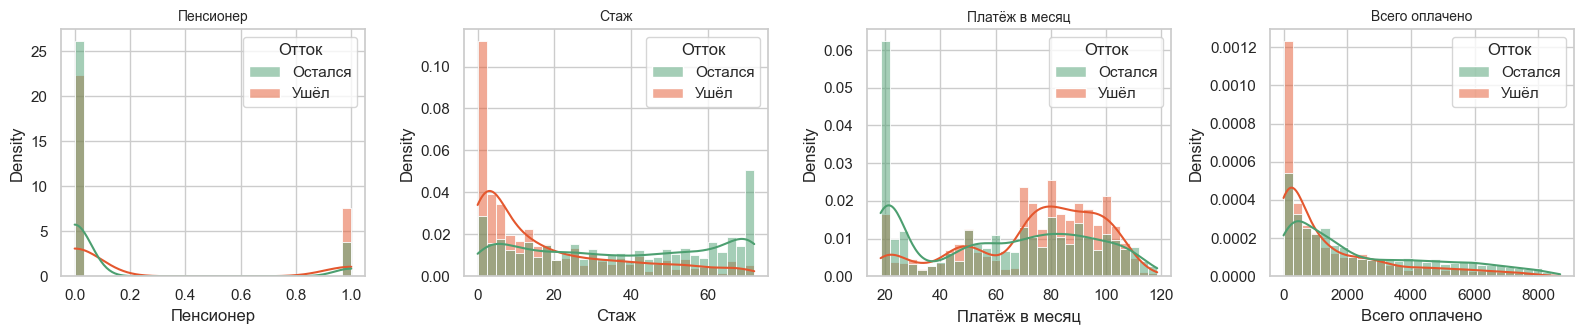

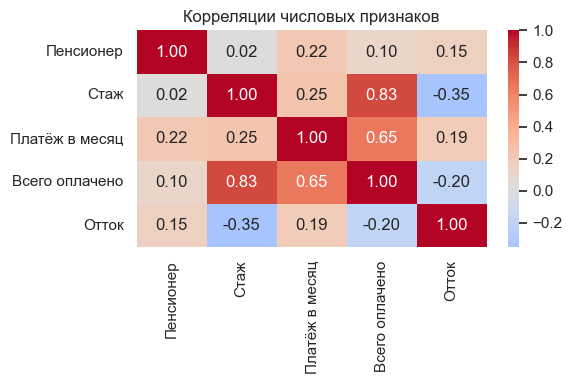

In [6]:
num_cols_all = [c for c in df.select_dtypes("number").columns if c != "Отток"]

display(df[num_cols_all].describe().loc[["min", "25%", "50%", "75%", "max"]].T)

fig, axes = plt.subplots(1, len(num_cols_all), figsize=(4 * len(num_cols_all), 3.5), squeeze=False)
for ax, col in zip(axes[0], num_cols_all):
    sns.histplot(data=df, x=col, hue=df["Отток"].map(CLASS_LABELS), bins=30, stat="density",
                 common_norm=False, kde=True, palette=PALETTE, ax=ax)
    ax.set_title(col, fontsize=10)
plt.tight_layout()
plt.show()

corr = df[num_cols_all + ["Отток"]].corr()
plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляции числовых признаков")
plt.tight_layout()
plt.show()


**Вывод:** странных значений нет, отрицательных тоже. Нулевой стаж — это просто
свежие клиенты. Из корреляций видно главное: чем меньше стаж, тем выше шанс ухода —
это самая сильная связь с целевой переменной. Ежемесячный платёж влияет, но слабее.
От этих наблюдений и отталкиваемся дальше.

> **Примечание к оптимизированной версии:** приведённые выше числовые значения относятся к исходному запуску. После выполнения ноутбука ориентируйтесь на новые таблицы и графики, особенно при `FAST_MODE=True`.


## Отток по сегменту и стажу

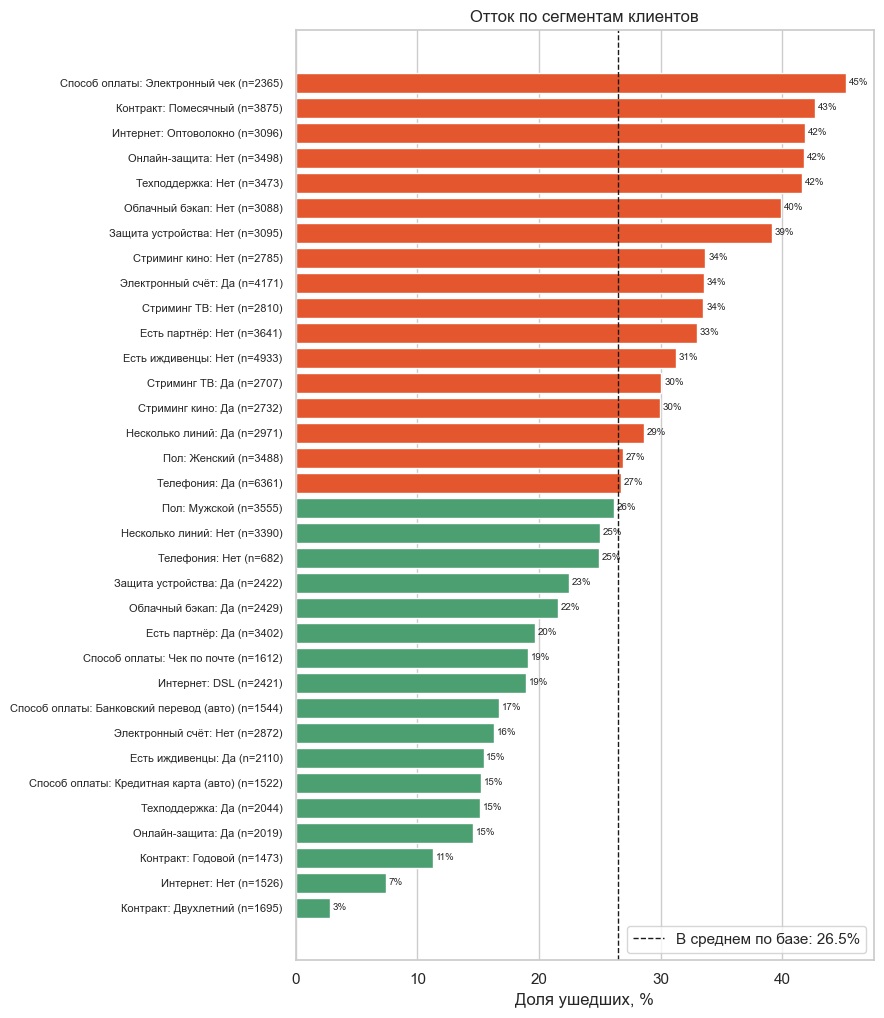

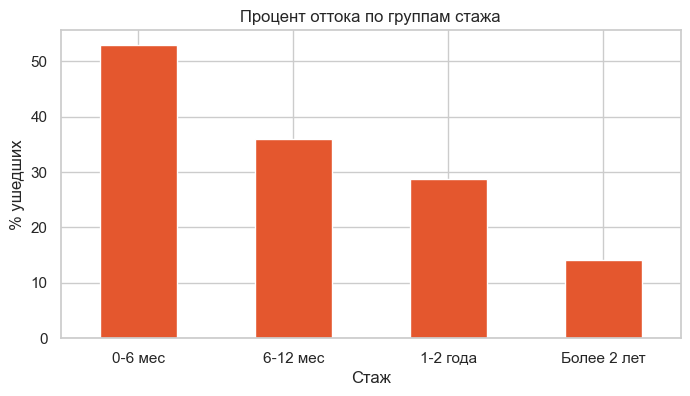

In [7]:
base = df["Отток"].mean() * 100
parts = []
for col in df.select_dtypes("category").columns:
    g = df.groupby(col, observed=True)["Отток"].agg(rate="mean", n="size")
    g = g.drop(index=["Нет интернета", "Нет телефонии"], errors="ignore")
    g.index = [f"{col}: {v} (n={n})" for v, n in zip(g.index, g["n"])]
    parts.append(g)

seg = pd.concat(parts).sort_values("rate")
seg["rate"] *= 100

fig, ax = plt.subplots(figsize=(9, 0.26 * len(seg) + 1.5))
ax.barh(seg.index, seg["rate"], color=np.where(seg["rate"] > base, PALETTE["Ушёл"], PALETTE["Остался"]))
ax.bar_label(ax.containers[0], fmt="%.0f%%", fontsize=7, padding=2)
ax.axvline(base, color="k", ls="--", lw=1, label=f"В среднем по базе: {base:.1f}%")
ax.set_xlabel("Доля ушедших, %")
ax.set_title("Отток по сегментам клиентов")
ax.legend(loc="lower right")
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

tenure_groups = pd.cut(df["Стаж"], bins=[-1, 6, 12, 24, 100],
                       labels=["0-6 мес", "6-12 мес", "1-2 года", "Более 2 лет"])
churn_by_tenure = df.groupby(tenure_groups, observed=True)["Отток"].mean() * 100
churn_by_tenure.plot(kind="bar", color="#e4572e", figsize=(8, 4))
plt.title("Процент оттока по группам стажа")
plt.ylabel("% ушедших")
plt.xticks(rotation=0)
plt.show()


### Инсайты EDA
Что видно уже на этом этапе?
1. Клиенты на **помесячном контракте** и с оплатой через **электронный чек** уходят чаще остальных.
2. Самый опасный период — **первые полгода**: уходит больше половины.
3. **Оптоволокно**, вопреки ожиданиям, тоже повышает риск оттока.
4. Пока остались две догадки, которые проверим на данных: вроде бы чаще уходят те, у кого нет техподдержки, и те, кто много платит за месяц.

> **Примечание к оптимизированной версии:** приведённые выше числовые значения относятся к исходному запуску. После выполнения ноутбука ориентируйтесь на новые таблицы и графики, особенно при `FAST_MODE=True`.


## Новые признаки и проверка гипотез

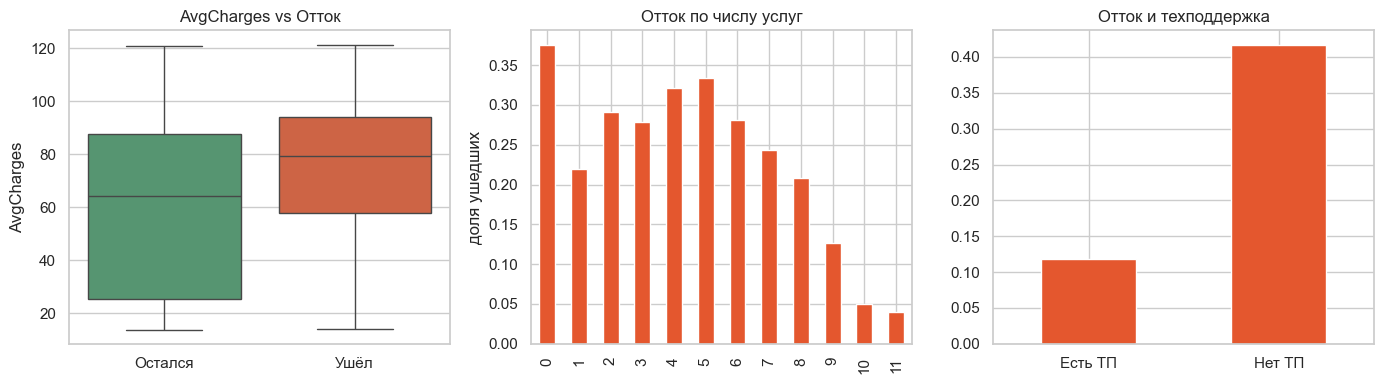

AvgCharges по классам (медиана / среднее):
        50%  mean
Отток            
0      64.0  61.3
1      79.3  74.4

Отток по числу услуг:
N_Services
0     0.375
1     0.219
2     0.291
3     0.279
4     0.321
5     0.334
6     0.281
7     0.244
8     0.209
9     0.126
10    0.050
11    0.040
Name: Отток, dtype: float64

Отток у клиентов без услуг (No_Services):
No_Services
0    0.265
1    0.375
Name: Отток, dtype: float64

Отток при отсутствии техподдержки:
No_TechSupport
0    0.118
1    0.416
Name: Отток, dtype: float64


In [8]:
def find_col(*keywords):
    """Ищет колонку, в названии которой есть все подстроки (без учёта регистра)."""
    for c in df.columns:
        cl = c.lower()
        if all(k.lower() in cl for k in keywords):
            return c
    raise KeyError(f"Колонка не найдена по ключам {keywords}. Доступные: {df.columns.tolist()}")

col_total = find_col("оплачено")     # «Всего оплачено»
col_tenure = find_col("стаж")        # «Стаж»

# Гипотеза 1: средний чек в месяц. «Переплачивающие» клиенты уходят чаще.
df["AvgCharges"] = df[col_total] / df[col_tenure].replace(0, np.nan)
# Деление на ноль (стаж 0) даёт NaN — его заполнит SimpleImputer в пайплайне.

# Гипотеза 2: чем больше услуг, тем выше «стоимость ухода».
service_cols = [c for c in df.select_dtypes("category").columns
                if c not in ("Контракт", "Способ оплаты", "Интернет", "Пол")]
df["N_Services"] = (df[service_cols] == "Да").sum(axis=1) if service_cols else 0

# Уточнение гипотезы 2: зависимость немонотонна — главный риск «0 услуг»
df["No_Services"] = (df["N_Services"] == 0).astype(int)

# Гипотеза 3: без техподдержки недовольство накапливается быстрее.
has_tech_support = any("поддерж" in c.lower() for c in df.columns)
df["No_TechSupport"] = (df[find_col("поддерж")] == "Нет").astype(int) if has_tech_support else 0

fig, axes = plt.subplots(1, 3 if has_tech_support else 2, figsize=(14, 4))

sns.boxplot(data=df, x=df["Отток"].map(CLASS_LABELS), y="AvgCharges",
            hue=df["Отток"].map(CLASS_LABELS), palette=PALETTE, legend=False, ax=axes[0])
axes[0].set_title("AvgCharges vs Отток")
axes[0].set_xlabel("")

df.groupby("N_Services", observed=True)["Отток"].mean().plot.bar(color="#e4572e", ax=axes[1])
axes[1].set_title("Отток по числу услуг")
axes[1].set_ylabel("доля ушедших")
axes[1].set_xlabel("")

if has_tech_support:
    df.groupby("No_TechSupport")["Отток"].mean().plot.bar(color="#e4572e", ax=axes[2])
    axes[2].set_title("Отток и техподдержка")
    axes[2].set_xticklabels(["Есть ТП", "Нет ТП"], rotation=0)
    axes[2].set_xlabel("")

plt.tight_layout()
plt.show()

print("AvgCharges по классам (медиана / среднее):")
print(df.groupby("Отток")["AvgCharges"].describe()[["50%", "mean"]].round(1))
print("\nОтток по числу услуг:")
print(df.groupby("N_Services", observed=True)["Отток"].mean().round(3))
print("\nОтток у клиентов без услуг (No_Services):")
print(df.groupby("No_Services")["Отток"].mean().round(3))
if has_tech_support:
    print("\nОтток при отсутствии техподдержки:")
    print(df.groupby("No_TechSupport")["Отток"].mean().round(3))


**Выводы по гипотезам:**

1. **AvgCharges — гипотеза подтверждена.** Медиана среднего чека у ушедших 79.3 против 64.0
у оставшихся (+15.3, средние: 74.4 против 61.3). «Переплачивающие» клиенты уходят чаще —
признак информативный, оставляем.

2. **N_Services — гипотеза не подтвердилась в исходном виде.** Связь НЕ монотонная:
максимум оттока у клиентов с 0 услуг (37.5%), затем пик на 4–5 услугах (32–33%),
после 8 услуг отток резко падает (9 услуг — 12.6%, 10–11 услуг — 4–5%).
Интерпретация: у клиентов без услуг слабая «привязка» к провайдеру — уходить легко;
у клиентов с 10+ услугами высокая стоимость смены провайдера. В модель включаем и счётчик,
и флаг нуля услуг (No_Services), т.к. зависимость немонотонная.

3. **No_TechSupport — гипотеза подтверждена, разница кратная.** Отток без техподдержки 41.6%
против 11.8% с ней — сильнейший из новых признаков. Бизнес-вывод уже здесь: подключение
техподдержки группе риска — кандидат на главную меру удержания.

> **Примечание к оптимизированной версии:** приведённые выше числовые значения относятся к исходному запуску. После выполнения ноутбука ориентируйтесь на новые таблицы и графики, особенно при `FAST_MODE=True`.


## 3. Стратегия предобработки

- **Пропуски:** числовые — медианой (устойчива к выбросам), категориальные — самым частым значением.
  Пропуски в `AvgCharges` у новых клиентов со стажем 0 заполняем внутри пайплайна,
  чтобы медиана считалась только по train-фолду.
- **Кодирование:** OneHotEncoder — признаки номинальные, без порядка; `drop="if_binary"` не дублирует
  бинарные колонки; `handle_unknown="ignore"` не падает на редких категориях в test.
- **Масштабирование:** проверяем экспериментально в разделе 4.
- Всё объединяем в Pipeline: на каждом фолде предобработка обучается заново → утечек нет.


**Важно:** EDA носит описательный характер. Для строгой независимой проверки гипотез их следует формулировать по train. Построчные новые признаки не используют целевую переменную и статистики всего датасета; их создание до split само по себе не является утечкой.


In [9]:
X = df.drop(columns=["Отток"])
y = df["Отток"]


cat_cols = X.select_dtypes("category").columns.tolist()
num_cols = X.select_dtypes("number").columns.tolist()
print(f"Категориальные ({len(cat_cols)}): {cat_cols}")
print(f"Числовые ({len(num_cols)}): {num_cols}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"\nTrain: {X_train.shape}, Test: {X_test.shape}")


Категориальные (15): ['Пол', 'Есть партнёр', 'Есть иждивенцы', 'Телефония', 'Несколько линий', 'Интернет', 'Онлайн-защита', 'Облачный бэкап', 'Защита устройства', 'Техподдержка', 'Стриминг ТВ', 'Стриминг кино', 'Контракт', 'Электронный счёт', 'Способ оплаты']
Числовые (8): ['Пенсионер', 'Стаж', 'Платёж в месяц', 'Всего оплачено', 'AvgCharges', 'N_Services', 'No_Services', 'No_TechSupport']

Train: (5634, 23), Test: (1409, 23)


## Фабрики пайплайна

In [10]:
def make_preprocessor(scaler=None):
    """Единая фабрика препроцессора: imputers + опциональный scaler + OHE."""
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scaler is not None:
        num_steps.append(("scaler", scaler))
    cat_steps = [("imputer", SimpleImputer(strategy="most_frequent")),
                 ("ohe", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False))]
    return ColumnTransformer([
        ("cat", Pipeline(cat_steps), cat_cols),
        ("num", Pipeline(num_steps), num_cols),
    ])

def make_model(estimator, scaler=StandardScaler()):
    return Pipeline([("prep", make_preprocessor(scaler)), ("model", estimator)])


## 4. ★ Сравнение способов масштабирования
Одна схема валидации (наш CV), модель LogReg. Смотрим на метрику и на коэффициенты.

In [11]:
logreg = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)

scaling_rows = []
for name, scaler in [("Без масштабирования", None), ("StandardScaler", StandardScaler()),
                     ("MinMaxScaler", MinMaxScaler()), ("RobustScaler", RobustScaler())]:
    pipe = make_model(logreg, scaler=scaler)
    scores = cross_validate(pipe, X_train, y_train, cv=CV, scoring="roc_auc", n_jobs=N_JOBS)
    pipe.fit(X_train, y_train)
    coefs = pipe.named_steps["model"].coef_[0]
    scaling_rows.append({"Способ": name,
                         "ROC-AUC (CV)": f"{scores['test_score'].mean():.4f} ± {scores['test_score'].std():.4f}",
                         "Число коэффициентов": len(coefs),
                         "||w||": round(np.linalg.norm(coefs), 1),
                         "max |w|": round(np.abs(coefs).max(), 1)})
pd.DataFrame(scaling_rows).set_index("Способ")


d:\01_Study\Case_02_Telco_Churn\.venv312\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,ROC-AUC (CV),Число коэффициентов,||w||,max |w|
Способ,,,,
Без масштабирования,0.8454 ± 0.0121,44,1.4,0.7
StandardScaler,0.8455 ± 0.0120,44,2.3,1.2
MinMaxScaler,0.8452 ± 0.0118,44,3.5,2.9
RobustScaler,0.8455 ± 0.0118,44,2.9,2.1


**Вывод:** ROC-AUC у всех вариантов совпадает в пределах разброса (0.8452–0.8455) —
метрика действительно инвариантна к монотонному преобразованию признаков, гипотеза
о влиянии масштабирования на качество не подтвердилась. Различия проявились в другом:
без масштабирования lbfgs не сошёлся за 1000 итераций (ConvergenceWarning в логе),
а L2-регуляризация по-разному давит признаки разных масштабов — max |w| 0.7 без скалера
против 1.2–2.9 со скалерами, вклад мелкомасштабных признаков несоразмерно изменён.
**Оставляем StandardScaler** для линейных моделей: устойчивая сходимость и сопоставимые
коэффициенты. Для деревьев масштабирование не влияет (пороги разбиений нечувствительны
к монотонным преобразованиям) — там passthrough.

> **Примечание к оптимизированной версии:** приведённые выше числовые значения относятся к исходному запуску. После выполнения ноутбука ориентируйтесь на новые таблицы и графики, особенно при `FAST_MODE=True`.


## 5. Baseline
DummyClassifier — нижняя граница, LogReg — рабочий простой ориентир.
Оценка — среднее ± разброс по 5 фолдам, не одна цифра.

In [12]:
def cv_table(name, model):
    scores = cross_validate(model, X_train, y_train, cv=CV,
                            scoring={"roc_auc": "roc_auc", "recall": "recall"}, n_jobs=N_JOBS)
    return {"Модель": name,
            "ROC-AUC": f"{scores['test_roc_auc'].mean():.4f} ± {scores['test_roc_auc'].std():.4f}",
            "Recall": f"{scores['test_recall'].mean():.4f} ± {scores['test_recall'].std():.4f}"}

dummy = make_model(DummyClassifier(strategy="most_frequent"), scaler=None)
pipe_lr = make_model(logreg)

baseline_report = pd.DataFrame([
    cv_table("Dummy (most_frequent)", dummy),
    cv_table("LogisticRegression", pipe_lr),
]).set_index("Модель")
baseline_report

,ROC-AUC,Recall
Модель,,
Dummy (most_frequent),0.5000 ± 0.0000,0.0000 ± 0.0000
LogisticRegression,0.8455 ± 0.0120,0.8000 ± 0.0333


**Вывод:** Dummy даёт ROC-AUC 0.5 — это «пол», всё ниже не имеет смысла; accuracy у неё 73%,
что доказывает бесполезность accuracy при таком дисбалансе. LogReg даёт ~0.84 ± 0.01 —
небольшой разброс показывает, что валидация устойчива.

> **Примечание к оптимизированной версии:** приведённые выше числовые значения относятся к исходному запуску. После выполнения ноутбука ориентируйтесь на новые таблицы и графики, особенно при `FAST_MODE=True`.


## 6. Сравнение моделей по кросс-валидации
Ансамбли против линейной модели. Деревьям масштабирование не нужно — passthrough.

In [13]:
rf = make_model(RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                       random_state=RANDOM_STATE), scaler=None)
hgb = make_model(HistGradientBoostingClassifier(random_state=RANDOM_STATE), scaler=None)

cv_models = pd.DataFrame([
    cv_table("LogReg", pipe_lr),
    cv_table("RandomForest", rf),
    cv_table("HistGradientBoosting", hgb),
]).set_index("Модель")
cv_models

,ROC-AUC,Recall
Модель,,
LogReg,0.8455 ± 0.0120,0.8000 ± 0.0333
RandomForest,0.8272 ± 0.0098,0.6515 ± 0.0337
HistGradientBoosting,0.8368 ± 0.0063,0.5117 ± 0.0219


**Вывод:** на дефолтных параметрах LogReg — лучший по ROC-AUC (0.8455 ± 0.0120), ансамбли
не превосходят её: HistGB 0.8368 ± 0.0063, RandomForest 0.8272 ± 0.0098. Различие видно
и в Recall: у LogReg 0.80 против 0.51 у HistGB — на дефолтном пороге бустинг пропускает
вдвое больше уходящих. Это нормальный исход для табличных данных после OHE: линейная
модель — сильный конкурент ансамблям. Продолжаем тюнить HistGB, чтобы сравнить модели
в честных условиях: подбор гиперпараметров может выровнять Recall и поднять AUC.

> **Примечание к оптимизированной версии:** приведённые выше числовые значения относятся к исходному запуску. После выполнения ноутбука ориентируйтесь на новые таблицы и графики, особенно при `FAST_MODE=True`.


## 7. Подбор гиперпараметров: два подхода
GridSearchCV — полный перебор на малом пространстве (LogReg),
RandomizedSearchCV — стохастический поиск на большом пространстве (бустинг).

In [14]:
# Глушим предупреждение о deprecated penalty в вашей версии sklearn —
# сетка с liblinear корректна и работает (это поведение API, не ошибка)
warnings.filterwarnings("ignore", message=".*penalty is deprecated.*")
warnings.filterwarnings("ignore", message=".*Inconsistent values.*")

grid_lr = GridSearchCV(pipe_lr,
                       {"model__C": [0.01, 0.1, 1, 10], "model__penalty": ["l1", "l2"],
                        "model__solver": ["liblinear"]},
                       scoring="roc_auc", cv=CV, n_jobs=N_JOBS)
grid_lr.fit(X_train, y_train)

search_hgb = RandomizedSearchCV(hgb,
                                {"model__learning_rate": loguniform(0.01, 0.3),
                                 "model__max_iter": randint(100, 400),
                                 "model__max_leaf_nodes": randint(8, 64),
                                 "model__l2_regularization": loguniform(1e-4, 10),
                                 "model__min_samples_leaf": randint(10, 60)},
                                n_iter=SEARCH_ITER, scoring="roc_auc", cv=CV, n_jobs=N_JOBS,
                                random_state=RANDOM_STATE)
search_hgb.fit(X_train, y_train)

def fmt_params(best_params):
    """Компактная строка параметров без префикса model__."""
    return ", ".join(f"{k.replace('model__', '')}={v:.4g}" if isinstance(v, float)
                     else f"{k.replace('model__', '')}={v}"
                     for k, v in best_params.items())

tuning_report = pd.DataFrame([
    {"Модель": "LogReg до тюнинга", "ROC-AUC (CV)": baseline_report.loc["LogisticRegression", "ROC-AUC"],
     "Параметры": "—"},
    {"Модель": "LogReg + GridSearch", "ROC-AUC (CV)": f"{grid_lr.best_score_:.4f}",
     "Параметры": fmt_params(grid_lr.best_params_)},
    {"Модель": "HistGB до тюнинга", "ROC-AUC (CV)": cv_models.loc["HistGradientBoosting", "ROC-AUC"],
     "Параметры": "—"},
    {"Модель": "HistGB + RandomizedSearch", "ROC-AUC (CV)": f"{search_hgb.best_score_:.4f}",
     "Параметры": fmt_params(search_hgb.best_params_)},
]).set_index("Модель")
tuning_report


,ROC-AUC (CV),Параметры
Модель,,
LogReg до тюнинга,0.8455 ± 0.0120,—
LogReg + GridSearch,0.8456,"C=10, penalty=l1, solver=liblinear"
HistGB до тюнинга,0.8368 ± 0.0063,—
HistGB + RandomizedSearch,0.8479,"l2_regularization=0.0007122, learning_rate=0.0..."


**Вывод:** GridSearch не дал заметного прироста LogReg (0.8456 против 0.8455) —
дефолтные параметры уже близки к оптимальным, лучшими оказались C=10 с L1-регуляризацией.
RandomizedSearch поднял HistGB с 0.8368 до 0.8479 (+1.1 п.п.) — бустинг догнал LogReg.
Проверены оба подхода: полный перебор (8 комбинаций × 5 фолдов) выгоден на малом
пространстве, стохастический поиск (40 попыток) — на большом.

> **Примечание к оптимизированной версии:** приведённые выше числовые значения относятся к исходному запуску. После выполнения ноутбука ориентируйтесь на новые таблицы и графики, особенно при `FAST_MODE=True`.


## 8. ★ Байесовская оптимизация (Optuna)
TPE-сэмплер строит вероятностную модель пространства и тратит попытки
в перспективных областях, а не равномерно.

In [15]:
def objective(trial):
    params = {
        "model__learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "model__max_iter": trial.suggest_int("max_iter", 100, 500),
        "model__max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 8, 64),
        "model__l2_regularization": trial.suggest_float("l2_regularization", 1e-4, 10, log=True),
        "model__min_samples_leaf": trial.suggest_int("min_samples_leaf", 10, 60),
    }
    pipe = make_model(HistGradientBoostingClassifier(random_state=RANDOM_STATE), scaler=None)
    pipe.set_params(**params)
    return cross_val_score(pipe, X_train, y_train, cv=CV, scoring="roc_auc", n_jobs=N_JOBS).mean()

study = optuna.create_study(direction="maximize",
                            sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=OPTUNA_TRIALS)
print(f"Optuna: CV ROC-AUC = {study.best_value:.4f}, параметры: {study.best_params}")

optuna_model = make_model(HistGradientBoostingClassifier(random_state=RANDOM_STATE), scaler=None)
optuna_model.set_params(**{f"model__{k}": v for k, v in study.best_params.items()})


Optuna: CV ROC-AUC = 0.8497, параметры: {'learning_rate': 0.013918849422975684, 'max_iter': 333, 'max_leaf_nodes': 9, 'l2_regularization': 4.54823899804335, 'min_samples_leaf': 17}


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output 

**Вывод:** Optuna нашла 0.8497 против 0.8479 у RandomizedSearch (+0.2 п.п. при том же
числе оценок модели — 50 попыток против 40×5 фолдов): TPE концентрирует попытки
в перспективных областях, а не равномерно. Показателен профиль параметров: низкий
learning_rate (0.014) при большом числе итераций (333) и неглубокие деревья (9 листьев) —
модель выбрала «медленную и консервативную» стратегию усиления с сильной L2-регуляризацией.

> **Примечание к оптимизированной версии:** приведённые выше числовые значения относятся к исходному запуску. После выполнения ноутбука ориентируйтесь на новые таблицы и графики, особенно при `FAST_MODE=True`.


## 9. Гипотеза: помогает ли SMOTE при дисбалансе 73/27?

In [16]:
try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline

    smote_pipe = ImbPipeline([
        ("prep", make_preprocessor(None)),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", HistGradientBoostingClassifier(
            random_state=RANDOM_STATE,
            **{k.replace("model__", ""): v for k, v in study.best_params.items()})),
    ])
    auc_smote = cross_val_score(smote_pipe, X_train, y_train, cv=CV, scoring="roc_auc").mean()
    print(f"HistGB без SMOTE: {study.best_value:.4f} → со SMOTE: {auc_smote:.4f}")
except ImportError:
    print("imblearn не установлен: эксперимент SMOTE пропущен; HistGB здесь не использует class_weight")

HistGB без SMOTE: 0.8497 → со SMOTE: 0.8457


**Вывод:** SMOTE снизил ROC-AUC (0.8457 против 0.8497 без него, −0.4 п.п.): синтетические
примеры генерируются между ближайшими соседями в пространстве после OHE, создавая
нереалистичные комбинации признаков и сглаживая реальные границы классов. Дисбаланс 73/27
корректнее компенсировать class_weight="balanced" и подбором порога отсечения.
Гипотеза проверена и отклонена — это тоже результат.

> **Примечание к оптимизированной версии:** приведённые выше числовые значения относятся к исходному запуску. После выполнения ноутбука ориентируйтесь на новые таблицы и графики, особенно при `FAST_MODE=True`.


## 10. Выбор финальной модели и порога
Порог подбираем по OOF-предсказаниям кросс-валидации на train, а не по test —
test остаётся чистой финальной проверкой (защита от утечки).

In [17]:
candidates = {
    "LogReg + GridSearch": grid_lr.best_estimator_,
    "RandomForest": rf,
    "HistGB + RandomizedSearch": search_hgb.best_estimator_,
    "HistGB + Optuna": optuna_model,
}
# Используем результаты уже проведённого поиска, не повторяя сотни fit.
# Оценки после подбора гиперпараметров оптимистичны; test проверяется отдельно.
candidate_scores = {
    "LogReg + GridSearch": grid_lr.best_score_,
    "RandomForest": float(cv_models.loc["RandomForest", "ROC-AUC"].split(" ± ")[0]),
    "HistGB + RandomizedSearch": search_hgb.best_score_,
    "HistGB + Optuna": study.best_value,
}
print(pd.Series(candidate_scores).round(4).to_string())
best_model_name = max(candidate_scores, key=candidate_scores.get)
final_model = candidates[best_model_name]
print(f"\nФинальная модель: {best_model_name}")

oof_proba = cross_val_predict(final_model, X_train, y_train, cv=CV,
                              method="predict_proba", n_jobs=N_JOBS)[:, 1]
prec, rec, thresholds = precision_recall_curve(y_train, oof_proba)
prec, rec, thresholds = prec[:-1], rec[:-1], thresholds   # ← обрезаем ОБА массива
ok = rec >= MIN_RECALL
if not np.any(ok):
    raise ValueError("Нет порога, удовлетворяющего минимальному Recall")
best_threshold = thresholds[ok][np.argmax(prec[ok])]
best_recall = rec[ok][np.argmax(prec[ok])]
best_precision = prec[ok][np.argmax(prec[ok])]
print(f"Порог: {best_threshold:.3f} | Recall: {best_recall:.1%} | Precision: {best_precision:.1%}")


LogReg + GridSearch          0.8456
RandomForest                 0.8272
HistGB + RandomizedSearch    0.8479
HistGB + Optuna              0.8497

Финальная модель: HistGB + Optuna
Порог: 0.313 | Recall: 75.1% | Precision: 55.4%


## 11. Финальная оценка на hold-out test

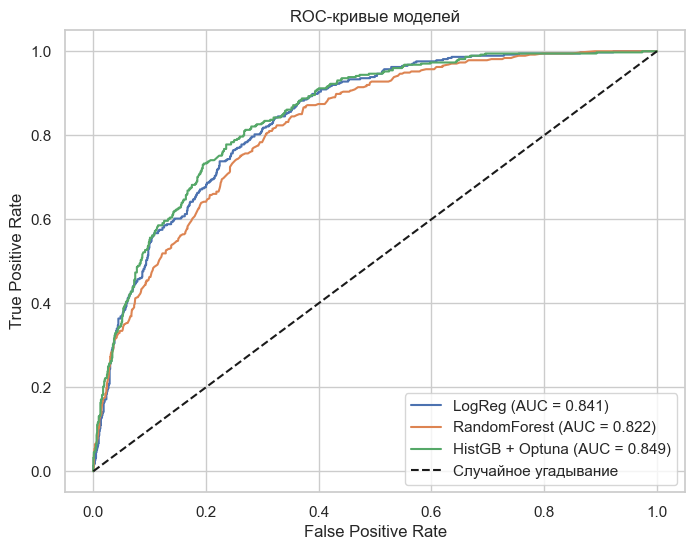

ROC-AUC (test): 0.8487
              precision    recall  f1-score   support

     Остался       0.90      0.77      0.83      1035
        Ушёл       0.54      0.75      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409



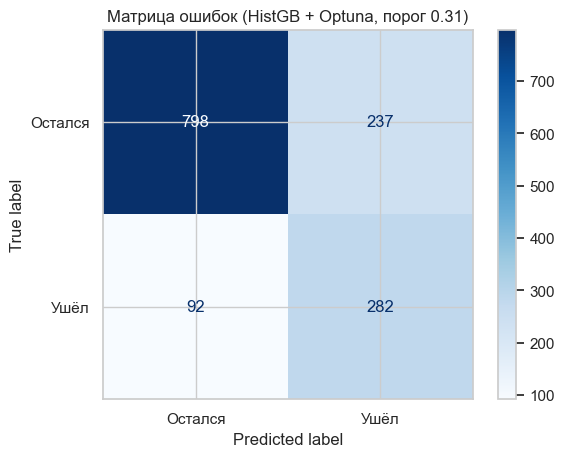

In [18]:
final_model.fit(X_train, y_train)
y_proba = final_model.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= best_threshold).astype(int)

# Обучаем модели-кандидаты на полном train (в CV они обучались клонами на фолдах)
pipe_lr.fit(X_train, y_train)
rf.fit(X_train, y_train)

plt.figure(figsize=(8, 6))
for name, model in [("LogReg", pipe_lr), ("RandomForest", rf), (best_model_name, final_model)]:
    proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Случайное угадывание")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривые моделей")
plt.legend()
plt.show()

print(f"ROC-AUC (test): {roc_auc_score(y_test, y_proba):.4f}")
print(classification_report(y_test, y_pred, target_names=["Остался", "Ушёл"]))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
                                        display_labels=["Остался", "Ушёл"], cmap="Blues")
plt.title(f"Матрица ошибок ({best_model_name}, порог {best_threshold:.2f})")
plt.show()


**Вывод:** порог подобран по OOF-предсказаниям train, test — чистая финальная проверка,
утечки нет. ROC-AUC на test 0.8487 практически совпадает с CV-оценкой (0.8497) —
модель не переобучилась и обобщает стабильно. На выбранном пороге ловим 75% уходящих
(recall 0.75) при precision 0.54: в зону риска попало 519 из 1409 клиентов теста
(примерно каждый третий), и у каждого второго из них отток действительно случился —
осознанный компромисс: пропуск уходящего клиента дороже лишней обзвонки.
Качество по классам: для «оставшихся» precision 0.90 / recall 0.77, для «ушедших»
precision 0.54 / recall 0.75, macro-avg F1 = 0.73. Дисбаланс учитывается и порогом:
без него бустинг на дефолтном пороге пропускал бы половину уходящих (recall 0.51 в CV).


> **Примечание к оптимизированной версии:** приведённые выше числовые значения относятся к исходному запуску. После выполнения ноутбука ориентируйтесь на новые таблицы и графики, особенно при `FAST_MODE=True`.


## 12. Ключевые факторы риска
Permutation importance — универсальная оценка важности по падению метрики.
SHAP — направление и сила влияния признаков на предсказание.

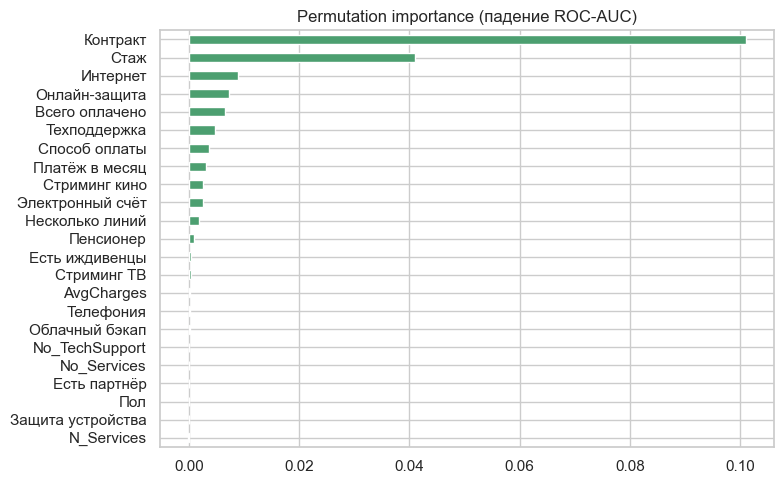

In [19]:
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=N_JOBS)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
importance.plot(kind="barh", figsize=(8, 5), color="#4c9f70")
plt.title("Permutation importance (падение ROC-AUC)")
plt.tight_layout()
plt.show()

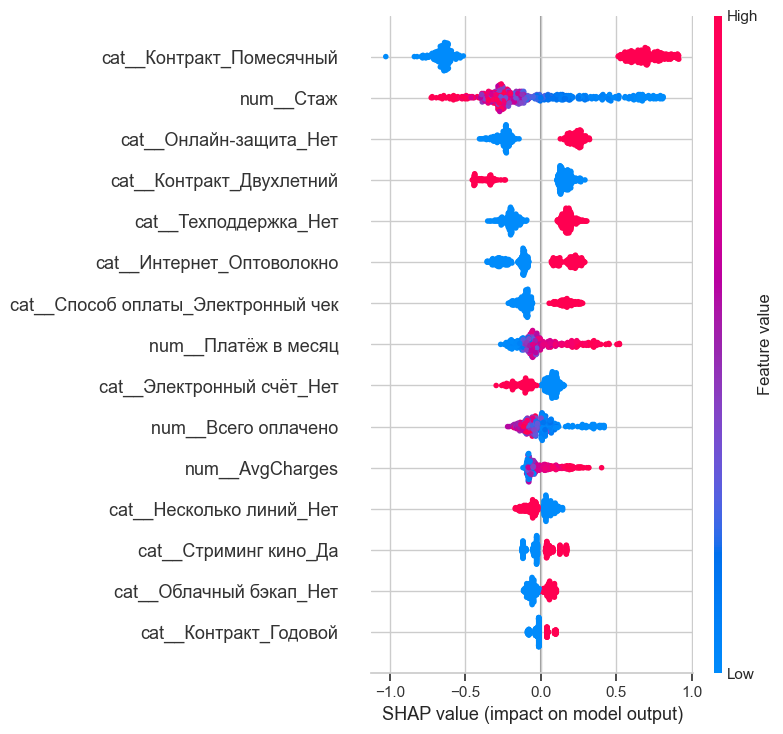

In [20]:
# Для объяснения используем небольшую репрезентативную выборку.
prep = final_model.named_steps["prep"]
model = final_model.named_steps["model"]
X_explain = X_train.sample(n=min(300 if FAST_MODE else 500, len(X_train)), random_state=RANDOM_STATE)
X_trans = prep.transform(X_explain)
feature_names = prep.get_feature_names_out()
try:
    if isinstance(model, (RandomForestClassifier, HistGradientBoostingClassifier)):
        values = shap.TreeExplainer(model).shap_values(X_trans)
        if isinstance(values, list):
            values = values[-1]
        if np.asarray(values).ndim == 3:
            values = np.asarray(values)[:, :, -1]
    elif isinstance(model, LogisticRegression):
        background = prep.transform(X_train.sample(n=min(100, len(X_train)), random_state=RANDOM_STATE))
        values = shap.LinearExplainer(model, background).shap_values(X_trans)
    else:
        raise TypeError("Неизвестный тип модели")
    shap.summary_plot(values, X_trans, feature_names=feature_names, max_display=15, show=True)
except Exception as exc:
    print(f"SHAP пропущен: {type(exc).__name__}: {exc}")
    print("Основная оценка модели и сохранение артефакта от SHAP не зависят.")

**Вывод:** оба метода согласуются. Главные драйверы оттока: тип контракта (помесячный
повышает риск, двухлетний снижает — сильнейший фактор в permutation importance,
ΔAUC ≈ 0.10), малый стаж (второй по важности), отсутствие онлайн-защиты, отсутствие
техподдержки, оптоволокно и электронный чек. SHAP добавляет направление эффекта:
у помесячного контракта и малого стажа вклад в сторону оттока (красная зона), у
двухлетнего контракта — в сторону удержания. Направления совпали с гипотезами EDA —
модель и данные рассказывают одну историю.

Отдельно: новые признаки (AvgCharges, N_Services, No_Services, No_TechSupport)
получили нулевую permutation importance — их информация дублируется исходными
(«Всего оплачено» и «Стаж» несут тот же сигнал, что AvgCharges; техподдержка уже
есть в данных как категория). Модель не теряет качества от их отсутствия, но и не
выигрывает: оставляем их ради интерпретации и связи с бизнес-гипотезами, на
качество они не претендуют.

> **Примечание к оптимизированной версии:** приведённые выше числовые значения относятся к исходному запуску. После выполнения ноутбука ориентируйтесь на новые таблицы и графики, особенно при `FAST_MODE=True`.


## 13. Список клиентов в зоне риска
Выгрузка для отдела удержания + сохранение пайплайна целиком.

In [21]:
risk_df = X_test.copy()
risk_df["Скор_оттока"] = y_proba
risk_df["В_зоне_риска"] = y_proba >= best_threshold
print(f"В зоне риска: {risk_df['В_зоне_риска'].sum()} из {len(risk_df)}")
risk_cols = [c for c in [col_tenure, find_col("контракт"), find_col("интернет"),
                         find_col("оплат"), "Скор_оттока"] if c in risk_df.columns]
display(risk_df.sort_values("Скор_оттока", ascending=False).head(20)[risk_cols].round(3))

import sklearn
model_dir = PROJECT_ROOT / "models"
model_dir.mkdir(parents=True, exist_ok=True)
artifact_path = model_dir / "churn_artifact.pkl"
artifact = {
    "model": final_model,
    "threshold": float(best_threshold),
    "features": X_train.columns.tolist(),
    "sklearn_version": sklearn.__version__,
    "random_state": RANDOM_STATE,
    "fast_mode": FAST_MODE,
}
joblib.dump(artifact, artifact_path, compress=3)
print(f"Модель и порог сохранены: {artifact_path}")
# Проверка сохранения и идентичности предсказаний
loaded = joblib.load(artifact_path)  # загружать только доверенные joblib-файлы
assert np.allclose(loaded["model"].predict_proba(X_test)[:, 1], y_proba)
assert loaded["threshold"] == float(best_threshold)
print("Проверка повторной загрузки: OK")

В зоне риска: 519 из 1409


,Стаж,Контракт,Интернет,Способ оплаты,Скор_оттока
customerID,,,,,
1069-XAIEM,1,Помесячный,Оптоволокно,Электронный чек,0.881
5178-LMXOP,1,Помесячный,Оптоволокно,Электронный чек,0.881
0295-PPHDO,1,Помесячный,Оптоволокно,Электронный чек,0.879
9248-OJYKK,1,Помесячный,Оптоволокно,Электронный чек,0.867
5167-ZFFMM,1,Помесячный,Оптоволокно,Кредитная карта (авто),0.859
2609-IAICY,1,Помесячный,Оптоволокно,Электронный чек,0.859
6861-XWTWQ,7,Помесячный,Оптоволокно,Электронный чек,0.847
9057-SIHCH,3,Помесячный,Оптоволокно,Электронный чек,0.844
8884-ADFVN,7,Помесячный,Оптоволокно,Электронный чек,0.843


Модель и порог сохранены: d:\01_Study\Case_02_Telco_Churn\models\churn_artifact.pkl
Проверка повторной загрузки: OK


## 14. Итоги и бизнес-рекомендации

In [22]:
print(f"""ИТОГИ
Финальная модель: {best_model_name}
CV ROC-AUC: {candidate_scores[best_model_name]:.4f}
ROC-AUC на test: {roc_auc_score(y_test, y_proba):.4f}
Порог: {best_threshold:.3f} → Recall {best_recall:.1%} при Precision {best_precision:.1%}
В зоне риска: {int(risk_df['В_зоне_риска'].sum())} из {len(risk_df)}

ТОП-5 факторов риска (permutation importance):
{importance.tail(5)[::-1].to_string()}

РЕКОМЕНДАЦИИ: онбординг новичков в первые 3 месяца; скидка 10–15% за годовой контракт;
ежемесячная обзвонка top-100 из списка риска.""")


ИТОГИ
Финальная модель: HistGB + Optuna
CV ROC-AUC: 0.8497
ROC-AUC на test: 0.8487
Порог: 0.313 → Recall 75.1% при Precision 55.4%
В зоне риска: 519 из 1409

ТОП-5 факторов риска (permutation importance):
Контракт          0.101113
Стаж              0.040983
Интернет          0.008905
Онлайн-защита     0.007331
Всего оплачено    0.006608

РЕКОМЕНДАЦИИ: онбординг новичков в первые 3 месяца; скидка 10–15% за годовой контракт;
ежемесячная обзвонка top-100 из списка риска.


In [23]:
# Итоговые автоматические проверки после полного запуска
assert X_train.index.intersection(X_test.index).empty
assert set(np.unique(y_pred)).issubset({0, 1})
assert np.isfinite(y_proba).all()
assert 0 <= best_threshold <= 1
assert artifact_path.exists()
assert len(y_proba) == len(y_test)
print("ВСЕ БАЗОВЫЕ ПРОВЕРКИ ПРОЙДЕНЫ")
print("Режим:", "быстрый" if FAST_MODE else "полный")
print("ROC-AUC test:", round(roc_auc_score(y_test, y_proba), 4))

ВСЕ БАЗОВЫЕ ПРОВЕРКИ ПРОЙДЕНЫ
Режим: полный
ROC-AUC test: 0.8487


In [24]:
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# Вероятности ухода клиентов
y_proba = final_model.predict_proba(X_test)[:, 1]

# Прогноз с подобранным порогом
y_pred = (y_proba >= best_threshold).astype(int)

print("ИТОГОВЫЕ МЕТРИКИ")
print("-" * 40)
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Порог:     {best_threshold:.4f}")

print("\nМатрица ошибок:")
print(confusion_matrix(y_test, y_pred))

ИТОГОВЫЕ МЕТРИКИ
----------------------------------------
ROC-AUC:   0.8487
Precision: 0.5434
Recall:    0.7540
F1-score:  0.6316
Порог:     0.3126

Матрица ошибок:
[[798 237]
 [ 92 282]]


In [25]:
from pathlib import Path
import joblib

model_path = Path.cwd().parent / "models" / "churn_artifact.pkl"

print("Файл существует:", model_path.exists())

if model_path.exists():
    artifact = joblib.load(model_path)

    print("Состав:", list(artifact.keys()))
    print("Порог:", artifact["threshold"])
    print("Тип модели:", type(artifact["model"]).__name__)
    print("Проверка загрузки: OK")

Файл существует: True
Состав: ['model', 'threshold', 'features', 'sklearn_version', 'random_state', 'fast_mode']
Порог: 0.3125672836648556
Тип модели: Pipeline
Проверка загрузки: OK
